In [1]:
import json
import ptwt
import torch


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
)
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset, DataLoader

In [2]:
EPOCHS = 100
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Success: Mac GPU (MPS) is available!")
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(41)
np.random.seed(41)

Success: Mac GPU (MPS) is available!


In [3]:
train_df = pd.read_csv("../../Data/train_data_features.csv")
dev_df = pd.read_csv("../../Data/dev_data_features.csv")
eval_df = pd.read_csv("../../Data/eval_data_features.csv")

In [4]:
def parse_array(value):
    return np.array(json.loads(value), dtype=np.float32)

In [5]:
def get_features_from_row(row):
    mfcc = parse_array(row["mcff"])
    sc = parse_array(row["sc"])
    sro = parse_array(row["sro"])
    cstft = parse_array(row["cstft"])
    zcr = parse_array(row["zcr"])
    rms = parse_array(row["rms"])

    return mfcc, sc, sro, cstft, zcr, rms

In [6]:
def build_feature_matrix(row):
    mfcc, sc, sro, cstft, zcr, rms = get_features_from_row(row)

    X = np.concatenate([
        mfcc,
        sc,
        sro,
        cstft,
        zcr,
        rms,
    ], axis=0)

    return X

In [7]:
class AudioFeaturesDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        X = build_feature_matrix(row)
        y = 0 if bool(row["is_bonafide"]) else 1
        X = torch.tensor(X, dtype=torch.float32)
        X = X.unsqueeze(0)
        y = torch.tensor(y, dtype=torch.long)

        return X, y

In [8]:
train_dataset = AudioFeaturesDataset(train_df)
dev_dataset = AudioFeaturesDataset(dev_df)
eval_dataset = AudioFeaturesDataset(eval_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=32,
    shuffle=False,
)

eval_loader = DataLoader(
    eval_dataset,
    batch_size=32,
    shuffle=False,
)

In [9]:
coefficients_relation = {"LL": 0, "LH": 0, "HL": 0, "HH": 0}

class WaveletPooling(nn.Module):
    def __init__(self, family="db6", level=1):
        super().__init__()
        self.family = family
        self.level = level

    def get_higest_energy_node(self, nodes):
        nodes_ranking = []

        for key, node in nodes.items():
            node_energy = torch.sum(node ** 2)
            nodes_ranking.append((key, node_energy))
        
        nodes_ranking = sorted(nodes_ranking, key=lambda item: -item[1])
        return nodes_ranking

    def forward(self, x):
        LL, (LH, HL, HH) = ptwt.wavedec2(x, wavelet=self.family, level=self.level, mode="zero")
        nodes = {"LL": LL, "LH": LH, "HL": HL, "HH": HH}
        highest_node_energy = self.get_higest_energy_node(nodes)
        
        coefficients_relation[highest_node_energy[0][0]] += 1

        return nodes[highest_node_energy[0][0]]


In [10]:
class WaveletCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            WaveletPooling(),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),

            WaveletPooling(),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),

            WaveletPooling(),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),

            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [11]:
model = WaveletCNN().to(device)

In [12]:
num_bonafide = int((train_df["is_bonafide"] == True).sum())
num_spoof = int((train_df["is_bonafide"] == False).sum())

print(num_bonafide, num_spoof)

total = num_bonafide + num_spoof

weight_bonafide = total / (2 * num_bonafide)
weight_spoof = total / (2 * num_spoof)

class_weights = torch.tensor(
    [weight_bonafide, weight_spoof],
    dtype=torch.float32
).to(device)

2580 22800


In [13]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

scheduler = ReduceLROnPlateau(
    optimizer, 
    mode='min',
    factor=0.1,
    patience=5,
    threshold=1e-4,
    min_lr=1e-6
)


In [14]:
class EarlyStopper:
    def __init__(self, patience=10):
        self.patience = patience
        self.counter = 0
        self.min_validation_loss = float('inf')

    def early_stop(self, validation_loss):
        if validation_loss < self.min_validation_loss:
            self.min_validation_loss = validation_loss
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience

In [15]:
def calculate_eer(labels, scores):
    fpr, tpr, thresholds = roc_curve(labels, scores)
    fnr = 1 - tpr
    idx = np.nanargmin(np.abs(fpr - fnr))
    eer = (fpr[idx] + fnr[idx]) / 2
    return eer

In [16]:

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X, y in loader:

        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X.size(0)
        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


In [17]:

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    for X, y in loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)
        loss = criterion(logits, y)
        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(logits, dim=1)
        running_loss += loss.item() * X.size(0)

        correct += (predictions == y).sum().item()
        total += y.size(0)

        all_labels.extend(y.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    eer = calculate_eer(
        all_labels,
        all_probabilities
    )

    return (
        epoch_loss,
        epoch_accuracy,
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities),
        eer
    )


In [18]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "dev_loss": [],
    "dev_accuracy": [],
}

best_dev_eer = float("inf")
best_model_state = None
best_model_status = {}

early_stopper = EarlyStopper(patience=20)
for epoch in range(EPOCHS):
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    dev_loss, dev_accuracy, _, _, _, eer = evaluate(
        model,
        dev_loader,
        criterion,
        device
    )

    scheduler.step(eer)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["dev_loss"].append(dev_loss)
    history["dev_accuracy"].append(dev_accuracy)

    if eer < best_dev_eer:
        best_dev_eer = eer
        best_model_state = {
            key: value.cpu().clone()
            for key, value in model.state_dict().items()
        }
        best_model_status = {
            "epoch": epoch+1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "dev_loss": dev_loss,
            "dev_accuracy": dev_accuracy,
            "best_dev_eer": best_dev_eer
        }

    if early_stopper.early_stop(eer):
        print("Early Stopping...")       
        break

    current_lr = optimizer.param_groups[0]['lr']

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"LR: {current_lr:.6f} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Dev Loss: {dev_loss:.4f} | "
        f"Dev Acc: {dev_accuracy:.4f} | "
        f"Dev ERR: {eer:.4f}"
    )

print(f"Best Model: {best_model_status}")


Epoch 01/100 | LR: 0.000100 | Train Loss: 0.6783 | Train Acc: 0.6363 | Dev Loss: 0.5409 | Dev Acc: 0.7665 | Dev ERR: 0.2696
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.5642 | Train Acc: 0.6866 | Dev Loss: 0.5665 | Dev Acc: 0.4636 | Dev ERR: 0.2068
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.4598 | Train Acc: 0.7626 | Dev Loss: 0.3306 | Dev Acc: 0.8489 | Dev ERR: 0.1479
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.3468 | Train Acc: 0.8240 | Dev Loss: 0.2682 | Dev Acc: 0.8405 | Dev ERR: 0.1247
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.2800 | Train Acc: 0.8497 | Dev Loss: 0.2544 | Dev Acc: 0.8521 | Dev ERR: 0.1117
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.2538 | Train Acc: 0.8591 | Dev Loss: 0.2453 | Dev Acc: 0.8887 | Dev ERR: 0.1033
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.2294 | Train Acc: 0.8731 | Dev Loss: 0.2457 | Dev Acc: 0.9069 | Dev ERR: 0.0981
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.2119 | Train Acc: 0.8852 | Dev Loss: 0.2063 | Dev Acc: 0.8983 | Dev ERR: 0.0827
Epoch 09

In [19]:
coefficients_relation

{'LL': 457161, 'LH': 0, 'HL': 0, 'HH': 0}

In [20]:
model.load_state_dict(best_model_state)
model.to(device)
model.eval()

WaveletCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): WaveletPooling()
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): WaveletPooling()
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): WaveletPooling()
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(1, 1))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.2, inplace=False)
    (5): Linear(in_features=64, out_features=2, bias=True)
  )
)

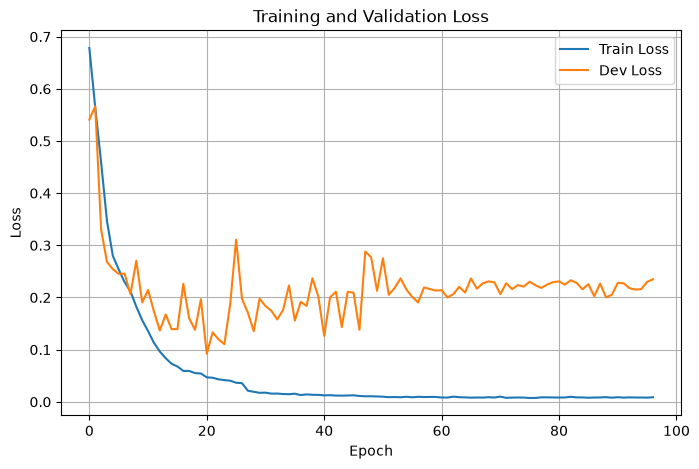

In [21]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["dev_loss"], label="Dev Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


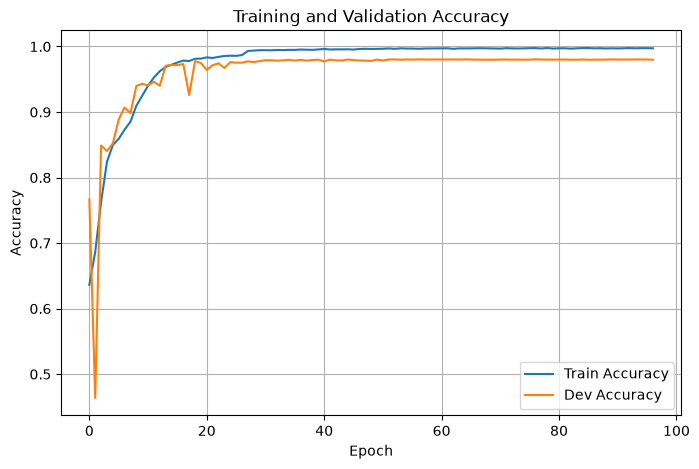

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_accuracy"], label="Train Accuracy")
plt.plot(history["dev_accuracy"], label="Dev Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


In [23]:
(
    eval_loss,
    eval_accuracy,
    eval_labels,
    eval_predictions,
    eval_probabilities,
    eer
) = evaluate(
    model,
    eval_loader,
    criterion,
    device
)

print(f"Eval Loss: {eval_loss:.4f}")
print(f"Eval Accuracy: {eval_accuracy:.4f}")
print(f"EER: {eer:.4f}")


Eval Loss: 0.4958
Eval Accuracy: 0.8790
EER: 0.1136


In [24]:
accuracy = accuracy_score(
    eval_labels,
    eval_predictions
)

precision = precision_score(
    eval_labels,
    eval_predictions,
    zero_division=0
)

recall = recall_score(
    eval_labels,
    eval_predictions,
    zero_division=0
)

f1 = f1_score(
    eval_labels,
    eval_predictions,
    zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


Accuracy : 0.8790
Precision: 0.9872
Recall   : 0.8764
F1-score : 0.9285


ROC AUC: 0.9593


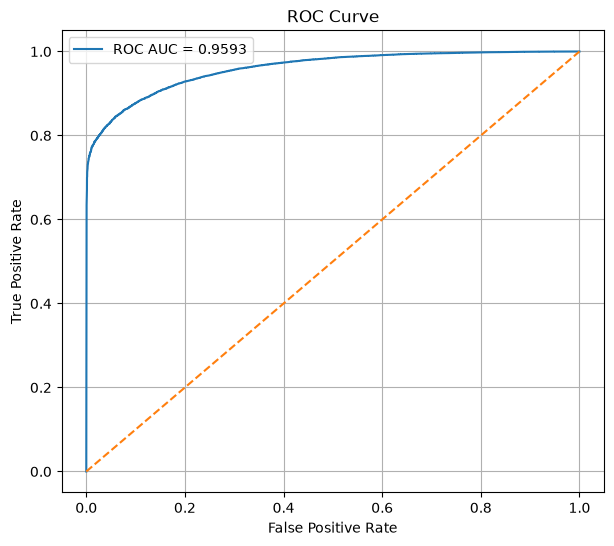

In [25]:

fpr, tpr, thresholds = roc_curve(
    eval_labels,
    eval_probabilities
)

roc_auc = auc(fpr, tpr)

print(f"ROC AUC: {roc_auc:.4f}")

plt.figure(figsize=(7, 6))
plt.plot(
    fpr,
    tpr,
    label=f"ROC AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()
